# 16. The Singular Value Decomposition
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

In [2]:
A = np.array([[3, 0], [4, 5.]])
U, s, Vt = np.linalg.svd(A)
print("singular values:", s, " vs 3*sqrt5, sqrt5 =", 3 * np.sqrt(5), np.sqrt(5))
print("U =\n", U.round(4), "\nV =\n", Vt.T.round(4)); print("A = U S V^T:", np.allclose(U @ np.diag(s) @ Vt, A))

singular values: [6.70820393 2.23606798]  vs 3*sqrt5, sqrt5 = 6.708203932499369 2.23606797749979
U =
 [[-0.3162 -0.9487]
 [-0.9487  0.3162]] 
V =
 [[-0.7071 -0.7071]
 [-0.7071  0.7071]]
A = U S V^T: True


The SVD of $A=\begin{bmatrix}3&0\\4&5\end{bmatrix}$ as three moves. The unit circle with the right singular vectors $v_1,v_2$ (left) is rotated by $V^{\mathsf T}$ so that $v_1,v_2$ lie on the axes, stretched by $\Sigma=\mathrm{diag}(3\sqrt5,\sqrt5)$, and rotated by $U$ onto the ellipse $A(\text{circle})$ with semi-axes $\sigma_1u_1$ and $\sigma_2u_2$ (right). A small shape rides along to show the orientation.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


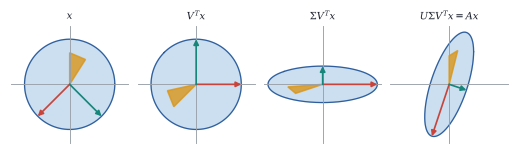

In [3]:
A = np.array([[3, 0], [4, 5.]]); U, s, Vt = np.linalg.svd(A)
if np.linalg.det(U) < 0: U[:, 1] *= -1; Vt[1] *= -1
t = np.linspace(0, 2 * np.pi, 300); C = np.vstack([np.cos(t), np.sin(t)])
flag = np.array([[0.0, 0.0, 0.35], [0.0, 0.7, 0.55]])
mats = [np.eye(2), Vt, np.diag(s) @ Vt, A]
titles = ["$x$", r"$V^{T}x$", r"$\Sigma V^{T}x$", r"$U\Sigma V^{T}x=Ax$"]
fig, axs = plt.subplots(1, 4, figsize=(W, 1.75))
for ax, M, ttl in zip(axs, mats, titles):
    lim = 1.3 if ttl in ("$x$", r"$V^{T}x$") else 7.2
    plane(ax, lim, grid=False); P = M @ C; ax.fill(*P, color=SKY, alpha=0.35); ax.plot(*P, color=BLUE, lw=0.8)
    ax.fill(*(M @ flag), color=GOLD, alpha=0.8)
    for k, col in [(0, RED), (1, TEAL)]:
        arrow(ax, M @ Vt[k], color=col, lw=1.1)
    ax.set_title(ttl, fontsize=6.5)

Filter factors. The pseudoinverse multiplies the component of $b$ along $u_k$ by $1/\sigma_k$ (grey dashed), which explodes for small $\sigma_k$. Ridge regularization uses $\sigma_k/(\sigma_k^2+\delta)$ (blue, for $\delta=10^{-2}$), equal to $1/\sigma_k$ for large $\sigma_k$ and to $\sigma_k/\delta$ for small ones; truncated SVD (gold) keeps $1/\sigma_k$ above a threshold and discards the rest.

(0.0011, 1200.0)

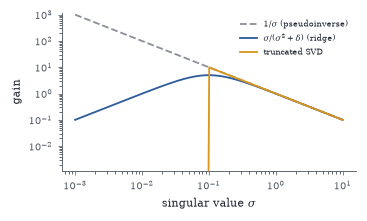

In [4]:
sig = np.logspace(-3, 1, 400); dl = 1e-2
fig, ax = plt.subplots(figsize=(W * 0.7, 1.9))
ax.loglog(sig, 1 / sig, "--", color=GRAY, label=r"$1/\sigma$ (pseudoinverse)")
ax.loglog(sig, sig / (sig ** 2 + dl), color=BLUE, label=r"$\sigma/(\sigma^2+\delta)$ (ridge)")
ax.loglog(sig, np.where(sig > 0.1, 1 / sig, 1e-3), color=GOLD, lw=1.2, label="truncated SVD")
ax.set_xlabel(r"singular value $\sigma$"); ax.set_ylabel("gain"); ax.legend(fontsize=5.5); ax.set_ylim(1e-3 * 1.1, 1.2e3)

Low-rank approximation of a $200\times200$ grayscale image (a synthetic test pattern). The truncated SVD $A_k$ for $k=1,5,20$ and the original, with the fraction of $\lVert A\rVert_F^2$ captured. Storing $A_k$ needs $k(m+n+1)$ numbers instead of $mn$: about $20\%$ of the storage at $k=20$. The plot at right shows the singular values, which decay quickly for structured images and slowly for noise.

Text(0.5, 0, '$k$')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


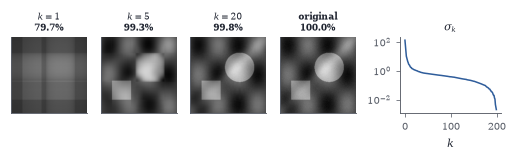

In [5]:
n = 200; x = np.linspace(-1, 1, n); X, Y = np.meshgrid(x, x)
img = (0.5 + 0.4 * np.sin(6 * X) * np.cos(4 * Y) + 0.6 * ((X - 0.3) ** 2 + (Y + 0.2) ** 2 < 0.15)
       + 0.5 * ((abs(X + 0.45) < 0.25) & (abs(Y - 0.4) < 0.25)) + 0.3 * np.exp(-((X + Y) ** 2) * 20))
img = img + 0.03 * np.random.default_rng(0).normal(size=img.shape)
U, s, Vt = np.linalg.svd(img)
fig, axs = plt.subplots(1, 5, figsize=(W, 1.35), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.25]})
for ax, k in zip(axs[:4], [1, 5, 20, n]):
    Ak = (U[:, :k] * s[:k]) @ Vt[:k]; ax.imshow(Ak, cmap="gray", vmin=0, vmax=2)
    ax.set_xticks([]); ax.set_yticks([]); frac = np.sum(s[:k] ** 2) / np.sum(s ** 2)
    ax.set_title(("original" if k == n else f"$k={k}$") + f"\n{100 * frac:.1f}%", fontsize=6)
axs[4].semilogy(s, color=BLUE, lw=1); axs[4].set_title(r"$\sigma_k$", fontsize=7); axs[4].set_xlabel("$k$")

Singular values of noise plus a rank-one signal $\theta uv^{\mathsf T}$, for a $1000\times500$ noise matrix. Below the threshold ($\theta=0.6$, left) all singular values lie in the Marchenko–Pastur bulk (curve) and the signal is invisible. Above it ($\theta=1.5$, right) one singular value separates from the bulk (red), close to the theoretical value $\sqrt{(1+\theta^2)(\theta^2+c)}/\theta$ with $c=1/2$ (dashed).

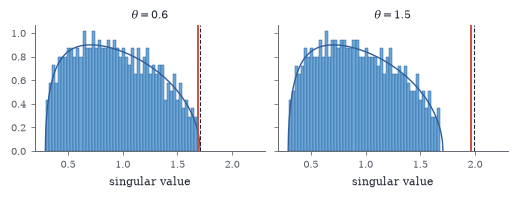

In [6]:
rng = np.random.default_rng(0); m, n = 1000, 500; c = n / m
Z = rng.normal(size=(m, n)) / np.sqrt(m); u = rng.normal(size=m); u /= np.linalg.norm(u); v = rng.normal(size=n); v /= np.linalg.norm(v)
lo, hi = 1 - np.sqrt(c), 1 + np.sqrt(c); xs = np.linspace(lo, hi, 400)
mp = np.sqrt(np.maximum((hi ** 2 - xs ** 2) * (xs ** 2 - lo ** 2), 0)) / (np.pi * c * xs)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.7), sharey=True)
for ax, th in zip(axs, [0.6, 1.5]):
    sv = np.linalg.svd(Z + th * np.outer(u, v), compute_uv=False)
    ax.hist(sv[1:], bins=50, density=True, color=SKY, edgecolor=BLUE, lw=0.3); ax.plot(xs, mp, color=BLUE, lw=0.9)
    ax.axvline(sv[0], color=RED, lw=1.2); pred = np.sqrt((1 + th ** 2) * (th ** 2 + c)) / th if th > c ** 0.25 else hi
    ax.axvline(pred, color=INK, ls="--", lw=0.7); ax.set_title(f"$\\theta={th}$", fontsize=7); ax.set_xlabel("singular value"); ax.set_xlim(0.2, 2.3)

The orthogonal Procrustes problem. Left: a reference shape $X$ (blue) and a rotated, noisy copy $Y$ (red). Right: the rotation $Q=UV^{\mathsf T}$ obtained from the SVD of $YX^{\mathsf T}$ aligns $X$ with $Y$ in the least squares sense, recovering the hidden rotation angle.

true angle 1.1   recovered 1.1252


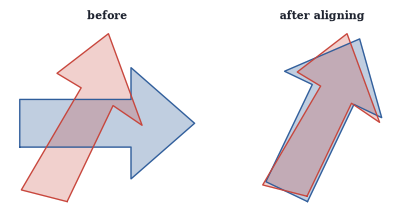

In [7]:
rng = np.random.default_rng(2); tt = np.linspace(0, 2 * np.pi, 9)[:-1]
Xs = np.array([[-1, 0.4, 0.4, 1.2, 0.4, 0.4, -1], [-0.3, -0.3, -0.7, 0, 0.7, 0.3, 0.3]]) + np.array([[0.1], [0.2]])
ang = 1.1; R = np.array([[np.cos(ang), -np.sin(ang)], [np.sin(ang), np.cos(ang)]]); Ys = R @ Xs + 0.08 * rng.normal(size=Xs.shape)
Us, ss, Vts = np.linalg.svd(Ys @ Xs.T); Qp = Us @ Vts
fig, axs = plt.subplots(1, 2, figsize=(W * 0.85, 1.9))
for ax, P, ttl in [(axs[0], Xs, "before"), (axs[1], Qp @ Xs, "after aligning")]:
    ax.fill(*P, color=BLUE, alpha=0.3); ax.plot(*np.c_[P, P[:, :1]], color=BLUE, lw=0.8)
    ax.fill(*Ys, color=RED, alpha=0.25); ax.plot(*np.c_[Ys, Ys[:, :1]], color=RED, lw=0.8)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(ttl, fontsize=7)
print("true angle", ang, "  recovered", round(np.arctan2(Qp[1, 0], Qp[0, 0]), 4))

In [8]:
rng = np.random.default_rng(0); G = rng.normal(size=(6, 4)) @ np.diag([10, 3, 1, 0.1]) @ rng.normal(size=(4, 4))
X = G / np.linalg.norm(G)                             # scale so all singular values are <= 1
for it in range(25):
    X = 1.5 * X - 0.5 * X @ X.T @ X                   # Newton-Schulz iteration
U, s, Vt = np.linalg.svd(G, full_matrices=False)
print("singular values of iterate:", np.linalg.svd(X, compute_uv=False).round(4)); print("equals U V^T:", np.allclose(X, U @ Vt, atol=1e-6))

singular values of iterate: [1. 1. 1. 1.]
equals U V^T: True


A linear map sends the unit circle to an ellipse with semi-axes $s_1,s_2$ (left) and the unit square aligned with the right singular vectors to a rectangle of area $s_1s_2$ (shaded, right), while the standard unit square becomes a parallelogram (outline) of the same area. Every shape's area is multiplied by $s_1s_2=\lvert\det A\rvert$.

Text(-2.4, 2.2, 'area $= 1.380 = |\\det A|$')

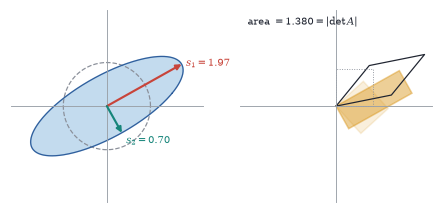

In [9]:
A = np.array([[1.5, 0.9], [0.3, 1.1]]); U, s, Vt = np.linalg.svd(A)
sg = np.sign(Vt[:, 0]); sg[sg == 0] = 1; Vt = Vt * sg[:, None]; U = U * sg[None, :]
t = np.linspace(0, 2 * np.pi, 300); C = np.vstack([np.cos(t), np.sin(t)])
fig, axs = plt.subplots(1, 2, figsize=(W * 0.85, 1.9))
plane(axs[0], 2.2, grid=False); unit_circle(axs[0]); axs[0].fill(*(A @ C), color=SKY, alpha=0.4); axs[0].plot(*(A @ C), color=BLUE, lw=0.8)
for k, col in [(0, RED), (1, TEAL)]:
    arrow(axs[0], s[k] * U[:, k], color=col)
    axs[0].text(*(s[k] * U[:, k] + (np.array([0.1, -0.05]) if k == 0 else np.array([0.1, -0.25]))), f"$s_{k + 1}={s[k]:.2f}$", color=col, fontsize=6.5)
sq = np.array([[0, 1, 1, 0], [0, 0, 1, 1.]]); V = Vt.T
plane(axs[1], 2.6, grid=False); axs[1].fill(*(A @ (V @ sq)), color=GOLD, alpha=0.45); axs[1].fill(*(V @ sq), color=GOLD, alpha=0.15)
axs[1].plot(*np.c_[A @ sq, (A @ sq)[:, :1]], color=INK, lw=0.8); axs[1].plot(*np.c_[sq, sq[:, :1]], color=GRAY, lw=0.6, ls=":")
axs[1].text(-2.4, 2.2, f"area $= {s[0] * s[1]:.3f} = |\\det A|$", fontsize=6.5)

In [10]:
A = np.array([[1, 1], [0, 1.]])
print("sigma(A)^2:", np.linalg.svd(A, compute_uv=False) ** 2, "   sigma(A^2):", np.linalg.svd(A @ A, compute_uv=False))
print("sigma(A A^T A):", np.linalg.svd(A @ A.T @ A, compute_uv=False), "  sigma(A)^3:", np.linalg.svd(A, compute_uv=False) ** 3)

sigma(A)^2: [2.61803399 0.38196601]    sigma(A^2): [2.41421356 0.41421356]
sigma(A A^T A): [4.23606798 0.23606798]   sigma(A)^3: [4.23606798 0.23606798]


In [11]:
rng = np.random.default_rng(0); x = rng.uniform(0.1, 3, 6); n = len(x)
A = np.zeros((n, n)); A[np.arange(n - 1), np.arange(1, n)] = np.sqrt(x[:-1]); A[n - 1, 0] = np.sqrt(x[-1])
lam = np.linalg.eigvals(A)
print("|eigenvalues|:", np.abs(lam).round(6), " (x1...xn)^(1/2n) =", round(np.prod(x) ** (1 / (2 * n)), 6))
print("AM =", x.mean().round(6), ">= GM =", round(np.prod(x) ** (1 / n), 6))

|eigenvalues|: [0.921641 0.921641 0.921641 0.921641 0.921641 0.921641]  (x1...xn)^(1/2n) = 0.921641
AM = 1.4003 >= GM = 0.849421


In [12]:
import itertools
A = np.array([[1, 2, 3], [2, 1, 3], [1, 1, 2.]])
d, r, c = max((abs(np.linalg.det(A[np.ix_(r, c)])), r, c) for r in itertools.combinations(range(3), 2) for c in itertools.combinations(range(3), 2))
B = A[np.ix_(r, c)]; Y = A[:, c] @ np.linalg.inv(B); Z = np.linalg.inv(B) @ A[r, :]
print("rows", r, "cols", c, "|det| =", round(d, 6)); print("Y =\n", Y.round(4), "\nZ =\n", Z.round(4), "\nA = Y B Z:", np.allclose(Y @ B @ Z, A))

rows (0, 1) cols (1, 2) |det| = 3.0
Y =
 [[ 1.     -0.    ]
 [ 0.      1.    ]
 [ 0.3333  0.3333]] 
Z =
 [[-1.  1.  0.]
 [ 1.  0.  1.]] 
A = Y B Z: True
